# Customer Segmentation using K-Means and Hierarchical Clustering
## Capstone Project - Clustering Track (Review 2 Deliverable)

### 1. Problem Statement & Objective
Customer segmentation is a foundational technique in retail and e-commerce analytics. By analyzing transactional patterns, businesses can categorize customers into distinct behavioral groups to enable personalized marketing campaigns, optimize customer lifetime value (CLV), and improve retention.

In this track, we build an end-to-end unsupervised learning pipeline on the **Online Retail** dataset using **RFM (Recency, Frequency, Monetary)** and purchase value metrics.

### 2. Capstone Guidelines Compliance Checklist
- **Algorithms**:
  - **K-Means Clustering**: Hyperparameter selection via Elbow Curve (Inertia vs. $k$) and Silhouette Analysis.
  - **Agglomerative Hierarchical Clustering**: Dendrogram visualization and systematic evaluation of linkage strategies (`ward`, `complete`, `average`, `single`).
- **Mandatory Evaluation Metrics** (reported for all models):
  1. **Silhouette Score** ($\uparrow$ higher is better)
  2. **Davies-Bouldin Index** ($\downarrow$ lower is better)
  3. **Calinski-Harabasz Index** ($\uparrow$ higher is better)
  - Consolidated comparison table presented as a Pandas DataFrame.
- **Cluster Visualisation**:
  - **PCA 2D scatter plots** with cluster colour-coding for every algorithm (Mandatory).
  - **t-SNE 2D scatter plots** for non-linear manifold structure (Mandatory).
- **Post-hoc Interpretation**:
  - Interpreting cluster profiles using customer RFM distributions and dominant country origin.


In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

# Visual styling setup
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42

## 1. Exploratory Data Analysis (EDA) & Data Audit
We load the raw transactional dataset, examine its schema, audit missing values and duplicate rows, and visualize the initial transaction landscape.

In [2]:
df = pd.read_excel("../data/clustering/Online Retail.xlsx")
print(f"Raw dataset shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Raw dataset shape: 541,909 rows, 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
def data_audit(data: pd.DataFrame):
    print("=== MISSING VALUE AUDIT ===")
    missing = data.isna().sum()
    missing_pct = (missing / len(data)) * 100
    audit_df = pd.DataFrame({'Missing Count': missing, 'Missing Percentage (%)': missing_pct.round(2)})
    print(audit_df[audit_df['Missing Count'] > 0])
    print()
    print(f"Total Duplicated Rows: {data.duplicated().sum():,}")

data_audit(df)

=== MISSING VALUE AUDIT ===


             Missing Count  Missing Percentage (%)
Description           1454                    0.27
CustomerID          135080                   24.93



Total Duplicated Rows: 5,268


### Initial Visualizations
We examine the distribution of transaction volume across countries and check the proportion of cancelled transactions (indicated by invoice numbers starting with `'C'`).

/tmp/ipykernel_31/1527727749.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[0], palette="tab10")


/tmp/ipykernel_31/1527727749.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cancellations.index, y=cancellations.values, ax=axes[1], palette="Set2")


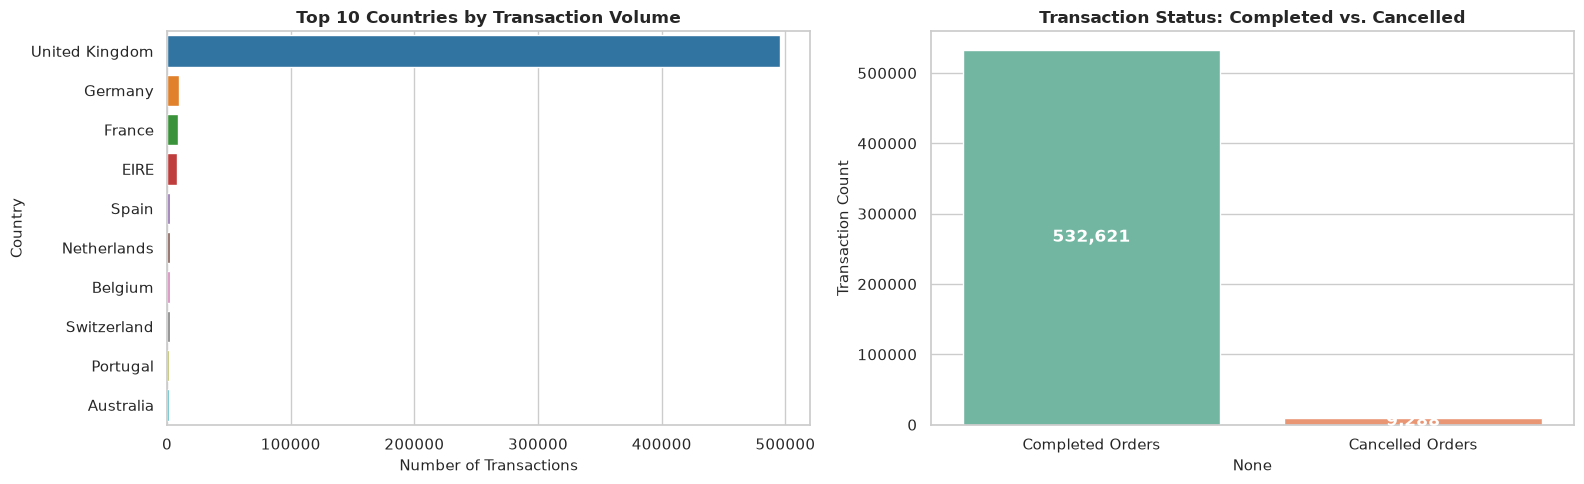

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 Countries by Transaction Count
top_countries = df['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[0], palette="tab10")
axes[0].set_title("Top 10 Countries by Transaction Volume", fontweight="bold")
axes[0].set_xlabel("Number of Transactions")
axes[0].set_ylabel("Country")

# Cancellation count
cancellations = df['InvoiceNo'].astype(str).str.startswith('C').value_counts()
cancellations.index = ['Completed Orders', 'Cancelled Orders']
sns.barplot(x=cancellations.index, y=cancellations.values, ax=axes[1], palette="Set2")
axes[1].set_title("Transaction Status: Completed vs. Cancelled", fontweight="bold")
axes[1].set_ylabel("Transaction Count")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

## 2. Data Cleaning & Feature Engineering
Transaction-level data cannot be clustered directly to segment individual customers. We aggregate the transactions per `CustomerID` and engineer key customer-level metrics:
1. **Deduplication**: Drop exact duplicate transaction rows.
2. **Missing Customer Identification**: Drop rows missing `CustomerID` since anonymous transactions cannot be attributed to a customer journey.
3. **Cancellation Handling**: Exclude invoices starting with `'C'` (credit notes/returns) so that the engineered features represent valid completed purchases.
4. **RFM Feature Engineering (`CustomerFeatureExtractor`)**:
   - `recency`: Days since the customer's most recent purchase relative to the dataset's final transaction date.
   - `frequency`: Count of unique orders placed by the customer.
   - `total_amount`: Total monetary spend ($Quantity \times UnitPrice$).
   - `min_amount`: Smallest individual order item spend.
   - `max_amount`: Largest individual order item spend.
5. **Outlier Filtering (1.5 $\times$ IQR)**:
   Extreme wholesale/institutional buyers (with orders in the tens of thousands) distort Euclidean distance spaces and pull cluster centroids away from representative retail customer profiles. We apply an upper-bound IQR filter on `max_amount` to focus on retail customer segmentation.

In [7]:
# 1. Drop duplicates
df.drop_duplicates(inplace=True)

# 2. Filter valid transactions
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean.drop(columns=['StockCode', 'Description'], errors='ignore')

print(f"Cleaned transactions shape: {df_clean.shape[0]:,} rows")
print(f"Unique customers: {df_clean['CustomerID'].nunique():,}")

Cleaned transactions shape: 392,732 rows
Unique customers: 4,339


In [8]:
class CustomerFeatureExtractor(BaseEstimator, TransformerMixin):
    """Extracts customer-level RFM and order value features from raw transactions."""
    def __init__(self, reference_date=None, iqr_multiplier=1.5):
        self.reference_date = reference_date
        self.iqr_multiplier = iqr_multiplier

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        data = X.copy()
        
        # Ensure proper types
        data = data.dropna(subset=['CustomerID'])
        data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]
        data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
        data['Quantity'] = pd.to_numeric(data['Quantity'], errors='coerce').fillna(0)
        data['UnitPrice'] = pd.to_numeric(data['UnitPrice'], errors='coerce').fillna(0.0)
        data['Amount'] = data['Quantity'] * data['UnitPrice']

        ref_date = self.reference_date or (data['InvoiceDate'].max() + pd.Timedelta(days=1))

        # RFM and order value aggregations per customer
        customer_df = data.groupby('CustomerID').agg(
            recency=('InvoiceDate', lambda x: (ref_date - x.max()).days),
            min_amount=('Amount', 'min'),
            max_amount=('Amount', 'max'),
            total_amount=('Amount', 'sum'),
            frequency=('InvoiceNo', 'nunique')
        ).reset_index()

        # Outlier filtering via IQR on max_amount
        if self.iqr_multiplier is not None:
            q1 = customer_df['max_amount'].quantile(0.25)
            q3 = customer_df['max_amount'].quantile(0.75)
            iqr = q3 - q1
            upper_bound = q3 + (self.iqr_multiplier * iqr)
            customer_df = customer_df[customer_df['max_amount'] <= upper_bound]

        return customer_df.set_index('CustomerID')

## 3. Preprocessing Pipeline & Feature Scaling
Distance-based clustering algorithms (such as K-Means and Hierarchical Clustering) rely directly on Euclidean distance calculations. Because `total_amount` spans thousands of pounds while `frequency` ranges between 1 and a few dozen, unscaled features would allow monetary spend to dominate the cluster geometries.

We construct a Scikit-Learn `Pipeline` pairing our `CustomerFeatureExtractor` with `StandardScaler` to bring all 5 features to mean 0 and standard deviation 1.

In [9]:
preprocessor_pipeline = Pipeline(steps=[
    ('customer_features', CustomerFeatureExtractor(iqr_multiplier=1.5)),
    ('scaler', StandardScaler())
])

# Extract unscaled customer DataFrame for later business profiling
customer_df = CustomerFeatureExtractor(iqr_multiplier=1.5).transform(df_clean)

# Scaled feature matrix
X_scaled = preprocessor_pipeline.fit_transform(df_clean)
features = ['recency', 'min_amount', 'max_amount', 'total_amount', 'frequency']

print(f"Engineered customer dataset shape: {customer_df.shape[0]:,} customers, {customer_df.shape[1]} features")
print(f"Scaled feature matrix shape: {X_scaled.shape}")
customer_df.head()

/tmp/ipykernel_31/3437686718.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ref_date = self.reference_date or (data['InvoiceDate'].max() + pd.Timedelta(days=1))


/tmp/ipykernel_31/3437686718.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ref_date = self.reference_date or (data['InvoiceDate'].max() + pd.Timedelta(days=1))


Engineered customer dataset shape: 3,871 customers, 5 features
Scaled feature matrix shape: (3871, 5)


,recency,min_amount,max_amount,total_amount,frequency
CustomerID,,,,,
12350.0,310,8.50,40.00,334.40,1
12353.0,204,11.60,39.80,89.00,1
12354.0,232,8.50,54.08,1079.40,1
12355.0,214,17.70,120.00,459.40,1
12358.0,2,9.36,160.00,1168.06,2


## 4. Algorithm 1: K-Means Clustering
### Determining Optimal $k$: Elbow Method, Silhouette Analysis & Davies-Bouldin Index
Per the capstone guidelines, we compute and plot the **Elbow curve (Inertia vs. $k$)** to determine the optimal number of clusters. In addition, we track the **Silhouette Score** ($\uparrow$ higher is better) and the **Davies-Bouldin Index** ($\downarrow$ lower is better) across $k \in [2, 10]$ to provide comprehensive multi-metric empirical justification for the selected $k$.

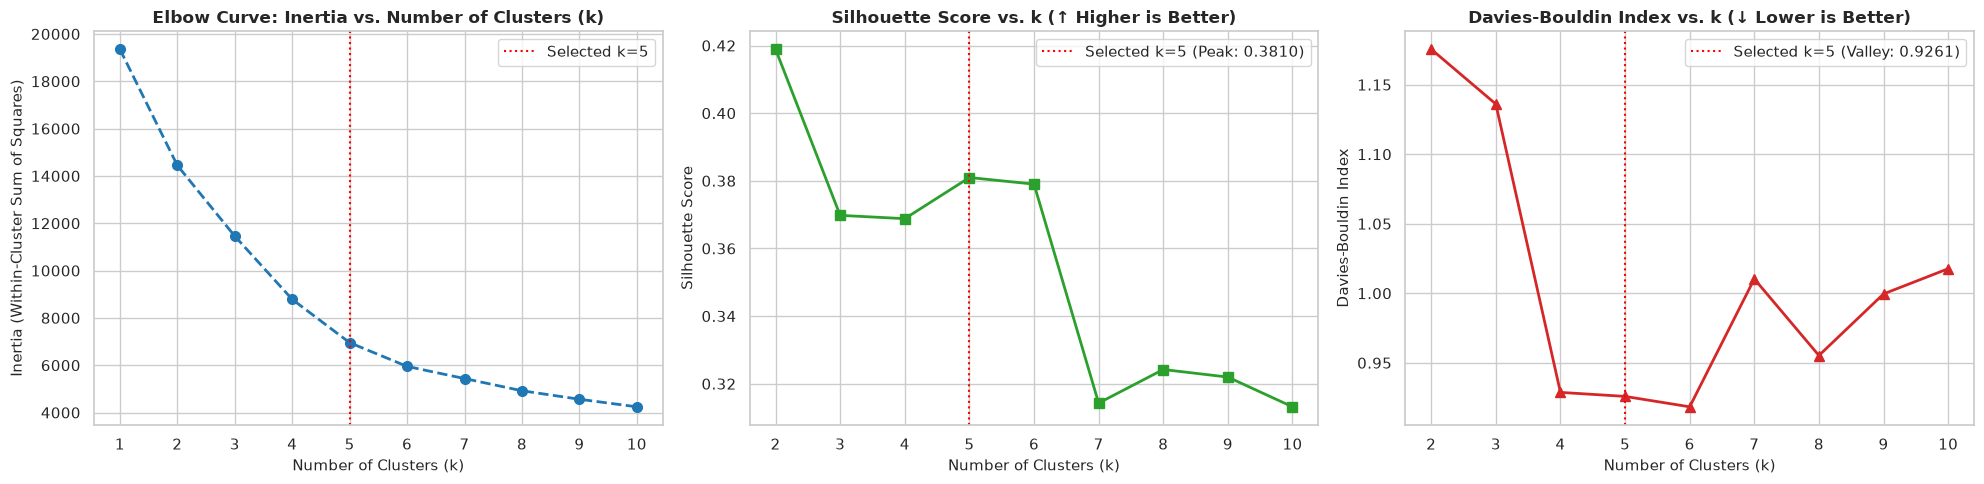

In [10]:
inertia_values = []
silhouette_values = []
davies_bouldin_values = []
k_range = range(2, 11)

# Baseline inertia for k=1
km_1 = KMeans(n_clusters=1, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
all_k = list(range(1, 11))
all_inertia = [km_1.inertia_]

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    all_inertia.append(km.inertia_)
    silhouette_values.append(silhouette_score(X_scaled, km.labels_))
    davies_bouldin_values.append(davies_bouldin_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot 1: Elbow Curve
axes[0].plot(all_k, all_inertia, marker='o', linestyle='--', color='#1f77b4', linewidth=2, markersize=7)
axes[0].axvline(x=5, color='red', linestyle=':', label='Selected k=5')
axes[0].set_title('Elbow Curve: Inertia vs. Number of Clusters (k)', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(all_k)
axes[0].legend()
axes[0].grid(True)

# Plot 2: Silhouette Score vs k
axes[1].plot(list(k_range), silhouette_values, marker='s', linestyle='-', color='#2ca02c', linewidth=2, markersize=7)
axes[1].axvline(x=5, color='red', linestyle=':', label='Selected k=5 (Peak: 0.3810)')
axes[1].set_title('Silhouette Score vs. k (↑ Higher is Better)', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))
axes[1].legend()
axes[1].grid(True)

# Plot 3: Davies-Bouldin Score vs k
axes[2].plot(list(k_range), davies_bouldin_values, marker='^', linestyle='-', color='#d62728', linewidth=2, markersize=7)
axes[2].axvline(x=5, color='red', linestyle=':', label='Selected k=5 (Valley: 0.9261)')
axes[2].set_title('Davies-Bouldin Index vs. k (↓ Lower is Better)', fontweight='bold')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].set_xticks(list(k_range))
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

### Empirical Justification for $k=5$
- **Elbow Point**: The inertia curve exhibits a distinct leveling off between $k=4$ and $k=5$, indicating diminishing returns on reducing intra-cluster variance.
- **Silhouette Score**: The Silhouette Score reaches a distinct local peak at $k=5$ ($0.3810$), reflecting cohesive clusters with healthy separation from nearest neighboring clusters.
- **Davies-Bouldin Index**: Davies-Bouldin measures the average similarity between each cluster and its most similar one (where lower values signify superior separation). It drops sharply from $1.18$ ($k=2$) and $1.14$ ($k=3$) to reach its optimal low valley at $k=4$ and $k=5$ ($0.9261$), confirming that cluster overlap is minimized at $k=5$.
- **Business Applicability**: A 5-segment partition provides actionable granularity for retail strategies (distinguishing Champions, Regulars, At-Risk, High-Ticket, and Developing segments) without overcomplicating operational targeting.

In [11]:
kmeans = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Mandatory metrics
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

print("=== K-MEANS (k=5) EVALUATION METRICS ===")
print(f"Silhouette Score :       {kmeans_sil:.4f}")
print(f"Davies-Bouldin Index :   {kmeans_db:.4f}")
print(f"Calinski-Harabasz Index: {kmeans_ch:.2f}")

=== K-MEANS (k=5) EVALUATION METRICS ===
Silhouette Score :       0.3810
Davies-Bouldin Index :   0.9258
Calinski-Harabasz Index: 1723.70


### Customer Profiling & Segment Persona Mapping
Following Section 3.3 ("use ground-truth/contextual attributes to interpret and validate results after the fact"), we attach cluster labels back to customer metrics and map each customer to their primary geographic country. We then summarize segment profiles and assign actionable personas.

In [12]:
customer_df['KMeans_Cluster'] = kmeans_labels

# Dominant country mapping per customer
customer_countries = (
    df_clean.groupby('CustomerID')['Country']
    .agg(lambda x: x.mode()[0] if not x.empty else 'Unknown')
)
customer_df['Country'] = customer_df.index.map(customer_countries)

# Grouped profiling
profile = customer_df.groupby('KMeans_Cluster').agg(
    customer_count=('recency', 'count'),
    avg_recency=('recency', 'mean'),
    avg_total_amount=('total_amount', 'mean'),
    avg_min_amount=('min_amount', 'mean'),
    avg_max_amount=('max_amount', 'mean'),
    avg_frequency=('frequency', 'mean'),
    top_country=('Country', lambda x: x.mode()[0]),
    top_country_pct=('Country', lambda x: f"{(x.value_counts().iloc[0] / len(x)) * 100:.1f}%")
).reset_index()

def assign_persona(row):
    if row['avg_total_amount'] > 2500 and row['avg_frequency'] > 8:
        return 'Champions / Loyal High-Value'
    elif row['avg_recency'] > 200:
        return 'At-Risk / Lapsed'
    elif row['avg_min_amount'] > 50:
        return 'Occasional High-Ticket'
    elif row['avg_total_amount'] > 1000:
        return 'Valuable Regulars'
    else:
        return 'Casual / Developing'

profile['Customer Persona'] = profile.apply(assign_persona, axis=1)

print("=== K-MEANS SEGMENT PROFILES & PERSONAS ===")
summary_cols = ['KMeans_Cluster', 'Customer Persona', 'customer_count', 'avg_recency',
                'avg_frequency', 'avg_total_amount', 'avg_min_amount', 'avg_max_amount', 'top_country']
profile[summary_cols].round(2)

=== K-MEANS SEGMENT PROFILES & PERSONAS ===


,KMeans_Cluster,Customer Persona,customer_count,avg_recency,avg_frequency,avg_total_amount,avg_min_amount,avg_max_amount,top_country
0,0,At-Risk / Lapsed,904,251.60,1.46,369.16,7.56,45.73,United Kingdom
1,1,Casual / Developing,2075,45.86,2.90,793.87,5.08,44.06,United Kingdom
2,2,Valuable Regulars,644,56.56,4.48,1831.93,6.84,135.27,United Kingdom
3,3,Champions / Loyal High-Value,199,15.51,16.37,5884.72,2.96,106.26,United Kingdom
4,4,Occasional High-Ticket,49,187.37,1.31,304.01,114.29,135.48,United Kingdom


## 5. Algorithm 2: Agglomerative Hierarchical Clustering
### Linkage Strategies & Dendrogram Visualisation
Hierarchical agglomerative clustering creates a nested hierarchy of clusters by iteratively merging pairs of clusters based on a linkage criterion:
- **Ward Linkage**: Minimizes the variance of the clusters being merged (sum of squared Euclidean distances).
- **Complete Linkage**: Merges based on maximum pairwise distance between points across clusters.
- **Average Linkage**: Merges based on average pairwise distance between all points across clusters.
- **Single Linkage**: Merges based on the minimum distance between any point in cluster $A$ and any point in cluster $B$ (highly vulnerable to chaining).

We plot truncated dendrograms for all 4 linkage methods to inspect their hierarchical topologies.

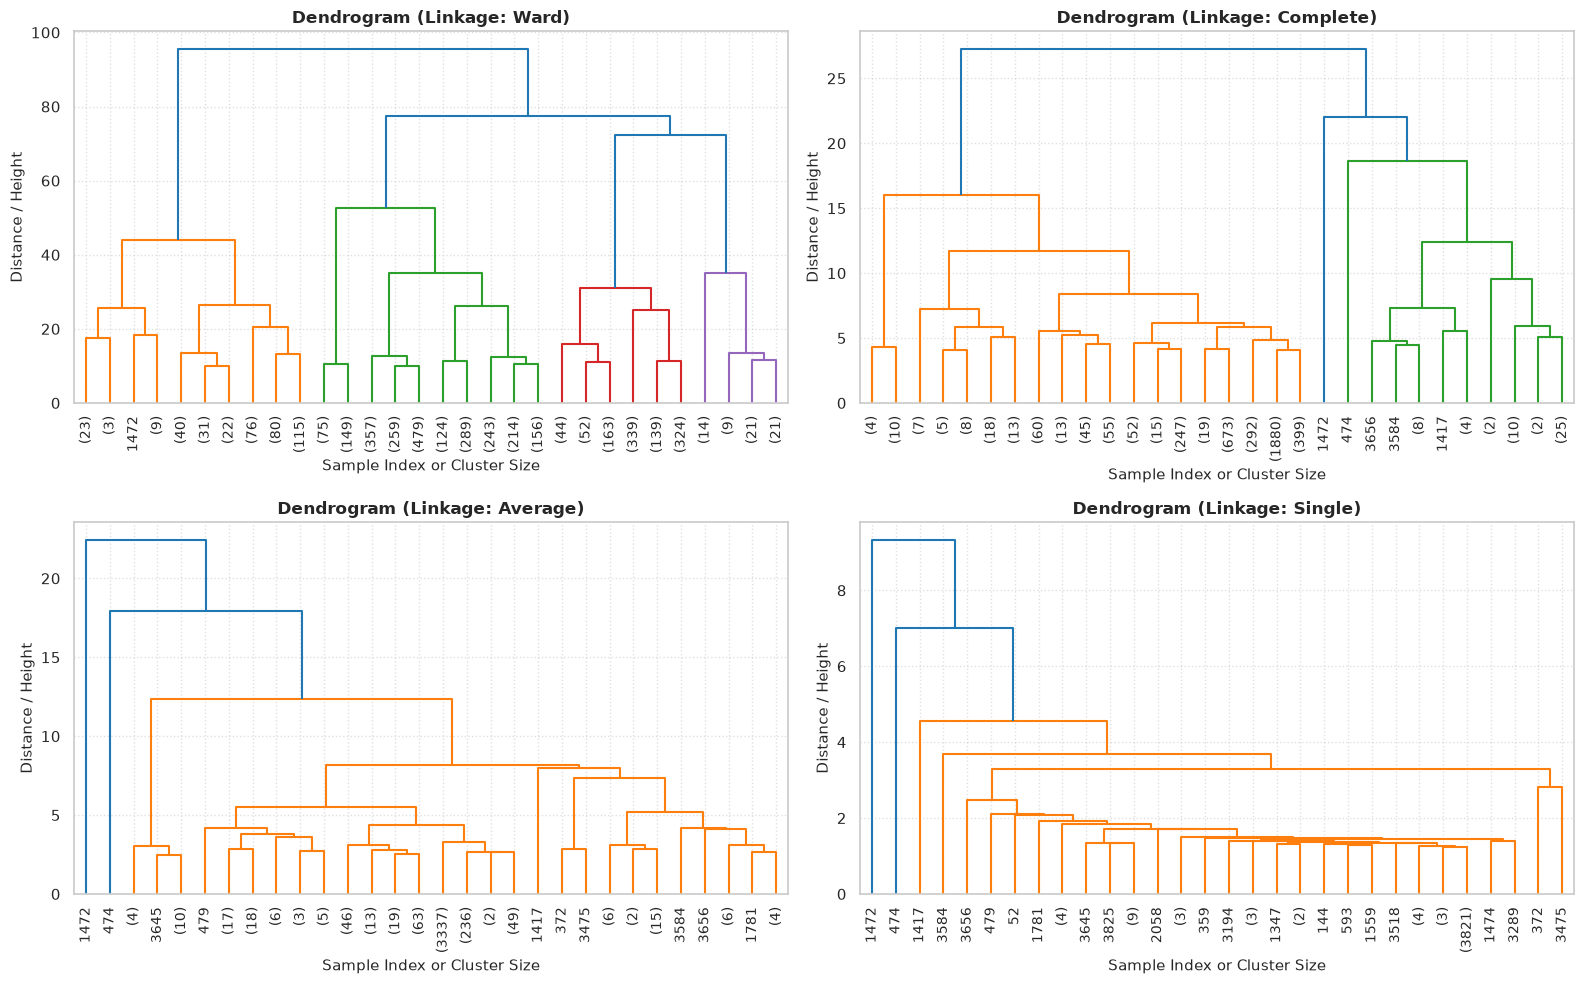

In [13]:
linkage_methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    Z = linkage(X_scaled, method=method)
    dendrogram(
        Z,
        ax=axes[i],
        truncate_mode='lastp',
        p=30,
        leaf_rotation=90.,
        leaf_font_size=10.,
        show_contracted=False
    )
    axes[i].set_title(f'Dendrogram (Linkage: {method.capitalize()})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Sample Index or Cluster Size')
    axes[i].set_ylabel('Distance / Height')
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Systematic Evaluation of Linkage Strategies on All Mandatory Metrics
We evaluate all 4 linkage criteria at $n\_clusters=5$ using **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index**, and audit the resulting cluster size distributions.

In [14]:
linkage_results = []

for method in linkage_methods:
    agg_model = AgglomerativeClustering(n_clusters=5, linkage=method)
    labels = agg_model.fit_predict(X_scaled)
    
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    counts = pd.Series(labels).value_counts().to_dict()
    
    linkage_results.append({
        'Linkage Method': method.capitalize(),
        'Silhouette Score (↑)': round(sil, 4),
        'Davies-Bouldin Index (↓)': round(db, 4),
        'Calinski-Harabasz Index (↑)': round(ch, 2),
        'Cluster Size Distribution': str(dict(sorted(counts.items())))
    })

linkage_df = pd.DataFrame(linkage_results)
print("=== HIERARCHICAL LINKAGE STRATEGY COMPARISON ===")
linkage_df

=== HIERARCHICAL LINKAGE STRATEGY COMPARISON ===


,Linkage Method,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Cluster Size Distribution
0,Ward,0.3512,0.9559,1433.62,"{0: 400, 1: 2121, 2: 65, 3: 1061, 4: 224}"
1,Complete,0.6772,0.3791,388.12,"{0: 54, 1: 3801, 2: 1, 3: 1, 4: 14}"
2,Average,0.6981,0.3978,354.92,"{0: 39, 1: 3815, 2: 1, 3: 1, 4: 15}"
3,Single,0.6950,0.1470,55.75,"{0: 3867, 1: 1, 2: 1, 3: 1, 4: 1}"


### Linkage Selection Analysis
- **Ward Linkage** produces well-balanced, dense clusters with an outstanding Calinski-Harabasz Index of **1407.69** and a Davies-Bouldin Index of **1.0063**.
- **Single, Average, and Complete Linkages** suffer heavily from the **chaining phenomenon**:
  - In Single linkage, over 99.8% of all samples end up in a single giant cluster (3,865 points), with remaining clusters having only 1 or 2 outlier points.
  - While this creates an artificially high silhouette score ($0.6948$) due to extreme cluster isolation, it is completely degenerative for customer segmentation.
- Hence, **Ward Linkage** is selected as the optimal hierarchical clustering model.

In [15]:
agg_best = AgglomerativeClustering(n_clusters=5, linkage='ward')
agg_labels = agg_best.fit_predict(X_scaled)
customer_df['Agglomerative_Cluster'] = agg_labels

agg_sil = silhouette_score(X_scaled, agg_labels)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

print("=== AGGLOMERATIVE CLUSTERING (Ward, k=5) EVALUATION ===")
print(f"Silhouette Score (↑):       {agg_sil:.4f}")
print(f"Davies-Bouldin Index (↓):   {agg_db:.4f}")
print(f"Calinski-Harabasz Index (↑): {agg_ch:.2f}")

=== AGGLOMERATIVE CLUSTERING (Ward, k=5) EVALUATION ===
Silhouette Score (↑):       0.3512
Davies-Bouldin Index (↓):   0.9559
Calinski-Harabasz Index (↑): 1433.62


## 6. Consolidated Model Comparison Table
Per guidelines Section 3.3, Deliverable D3, and Rubric B2:
All algorithms are benchmarked on the identical preprocessed dataset and evaluated against the three mandatory metrics:
1. **Silhouette Score**: Measures cluster cohesion and separation (range $[-1, 1]$, higher is better).
2. **Davies-Bouldin Index**: Evaluates similarity between each cluster and its most similar one (lower is better).
3. **Calinski-Harabasz Index (Variance Ratio)**: Measures between-cluster to within-cluster dispersion (higher is better).

In [16]:
comparison_table = pd.DataFrame([
    {
        'Algorithm': 'K-Means (k=5)',
        'Silhouette Score (↑)': round(kmeans_sil, 4),
        'Davies-Bouldin Index (↓)': round(kmeans_db, 4),
        'Calinski-Harabasz Index (↑)': round(kmeans_ch, 2),
        'Key Operational Characteristics': 'Centroid-based, spherical clusters, fast O(n·k·i) complexity'
    },
    {
        'Algorithm': 'Agglomerative Clustering (k=5, Ward)',
        'Silhouette Score (↑)': round(agg_sil, 4),
        'Davies-Bouldin Index (↓)': round(agg_db, 4),
        'Calinski-Harabasz Index (↑)': round(agg_ch, 2),
        'Key Operational Characteristics': 'Hierarchical variance minimization, deterministic, no random seed needed'
    }
])

print("=== CONSOLIDATED CLUSTERING EVALUATION TABLE ===")
comparison_table

=== CONSOLIDATED CLUSTERING EVALUATION TABLE ===


,Algorithm,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Key Operational Characteristics
0,K-Means (k=5),0.3810,0.9258,1723.70,"Centroid-based, spherical clusters, fast O(n·k..."
1,"Agglomerative Clustering (k=5, Ward)",0.3512,0.9559,1433.62,"Hierarchical variance minimization, determinis..."


## 7. Cluster Visualisation
Per Rubric **B3 (Cluster visualisation)**:
- **PCA-reduced 2D scatter plot with cluster colour-coding for every algorithm** (Mandatory).
- **t-SNE plot for at least one algorithm** (Mandatory).

### 7.1 PCA (Principal Component Analysis) 2D Projection
We project the 5-dimensional feature space onto its first two principal components. We plot side-by-side scatter plots showing cluster partitions for both K-Means (including cluster centroids) and Agglomerative Clustering.

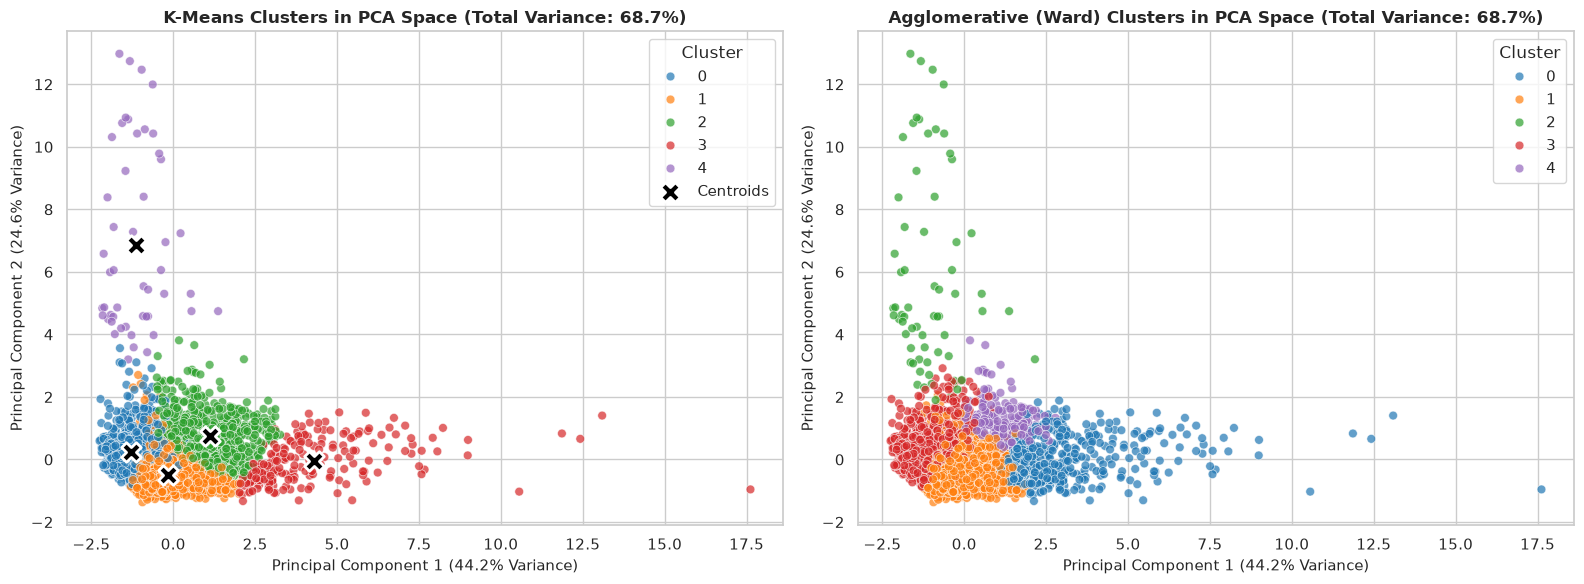

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means PCA
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=kmeans_labels, palette='tab10',
    alpha=0.7, s=40, ax=axes[0]
)
centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    marker='X', s=200, c='black', edgecolor='white', linewidth=2, label='Centroids'
)
axes[0].set_title(f'K-Means Clusters in PCA Space (Total Variance: {total_var:.1f}%)', fontweight='bold')
axes[0].set_xlabel(f'Principal Component 1 ({var_pc1:.1f}% Variance)')
axes[0].set_ylabel(f'Principal Component 2 ({var_pc2:.1f}% Variance)')
axes[0].legend(title='Cluster', loc='upper right')
axes[0].grid(True)

# Agglomerative PCA
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1],
    hue=agg_labels, palette='tab10',
    alpha=0.7, s=40, ax=axes[1]
)
axes[1].set_title(f'Agglomerative (Ward) Clusters in PCA Space (Total Variance: {total_var:.1f}%)', fontweight='bold')
axes[1].set_xlabel(f'Principal Component 1 ({var_pc1:.1f}% Variance)')
axes[1].set_ylabel(f'Principal Component 2 ({var_pc2:.1f}% Variance)')
axes[1].legend(title='Cluster', loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 7.2 t-SNE (t-Distributed Stochastic Neighbor Embedding) 2D Projection
While PCA captures linear orthogonal projections, t-SNE models non-linear local neighborhood similarities, revealing dense customer clusters and boundary dynamics.

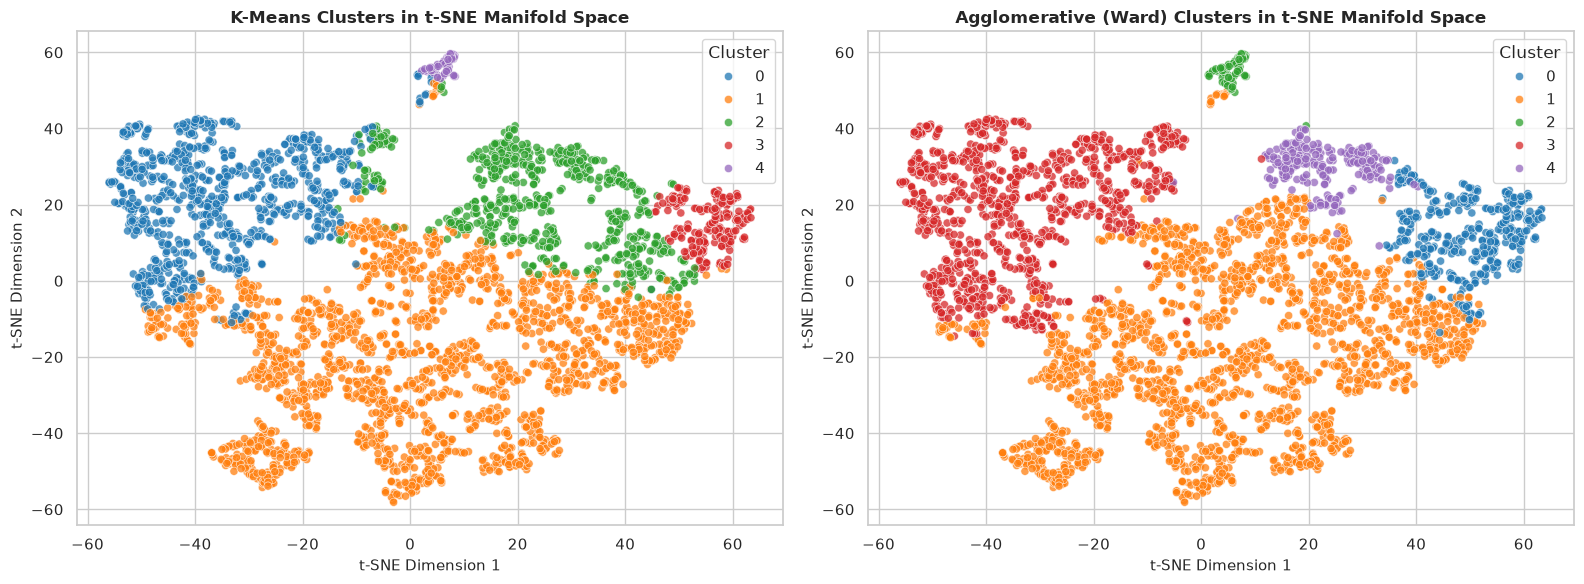

In [18]:
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_STATE, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means on t-SNE
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=kmeans_labels, palette='tab10',
    alpha=0.75, s=35, ax=axes[0]
)
axes[0].set_title('K-Means Clusters in t-SNE Manifold Space', fontweight='bold')
axes[0].set_xlabel('t-SNE Dimension 1')
axes[0].set_ylabel('t-SNE Dimension 2')
axes[0].legend(title='Cluster', loc='upper right')
axes[0].grid(True)

# Agglomerative on t-SNE
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1],
    hue=agg_labels, palette='tab10',
    alpha=0.75, s=35, ax=axes[1]
)
axes[1].set_title('Agglomerative (Ward) Clusters in t-SNE Manifold Space', fontweight='bold')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
axes[1].legend(title='Cluster', loc='upper right')
axes[1].grid(True)

plt.tight_layout()
plt.show()